## DQE gate-based optimisation

Optimises 3 piecewise-constant J channels on a 4-spin nearest-neighbour chain to
implement a target DQE gate (rotation in the |0011⟩ ↔ |1100⟩ subspace).

Gate entanglement measure: `operator_entanglement_sum_4q` — sum of operator
entanglement over all 7 bipartitions of the 4-qubit gate.

In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.dqe_gate import dqe_gate_optimisation
from pulse_vqe_entanglement.plotting_gate import plot_dqe_gate_optimisation

Tracing control amplitude graph.
GI=1.661e-05, nit=500, success=False, grad_norm=1.273e-04
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


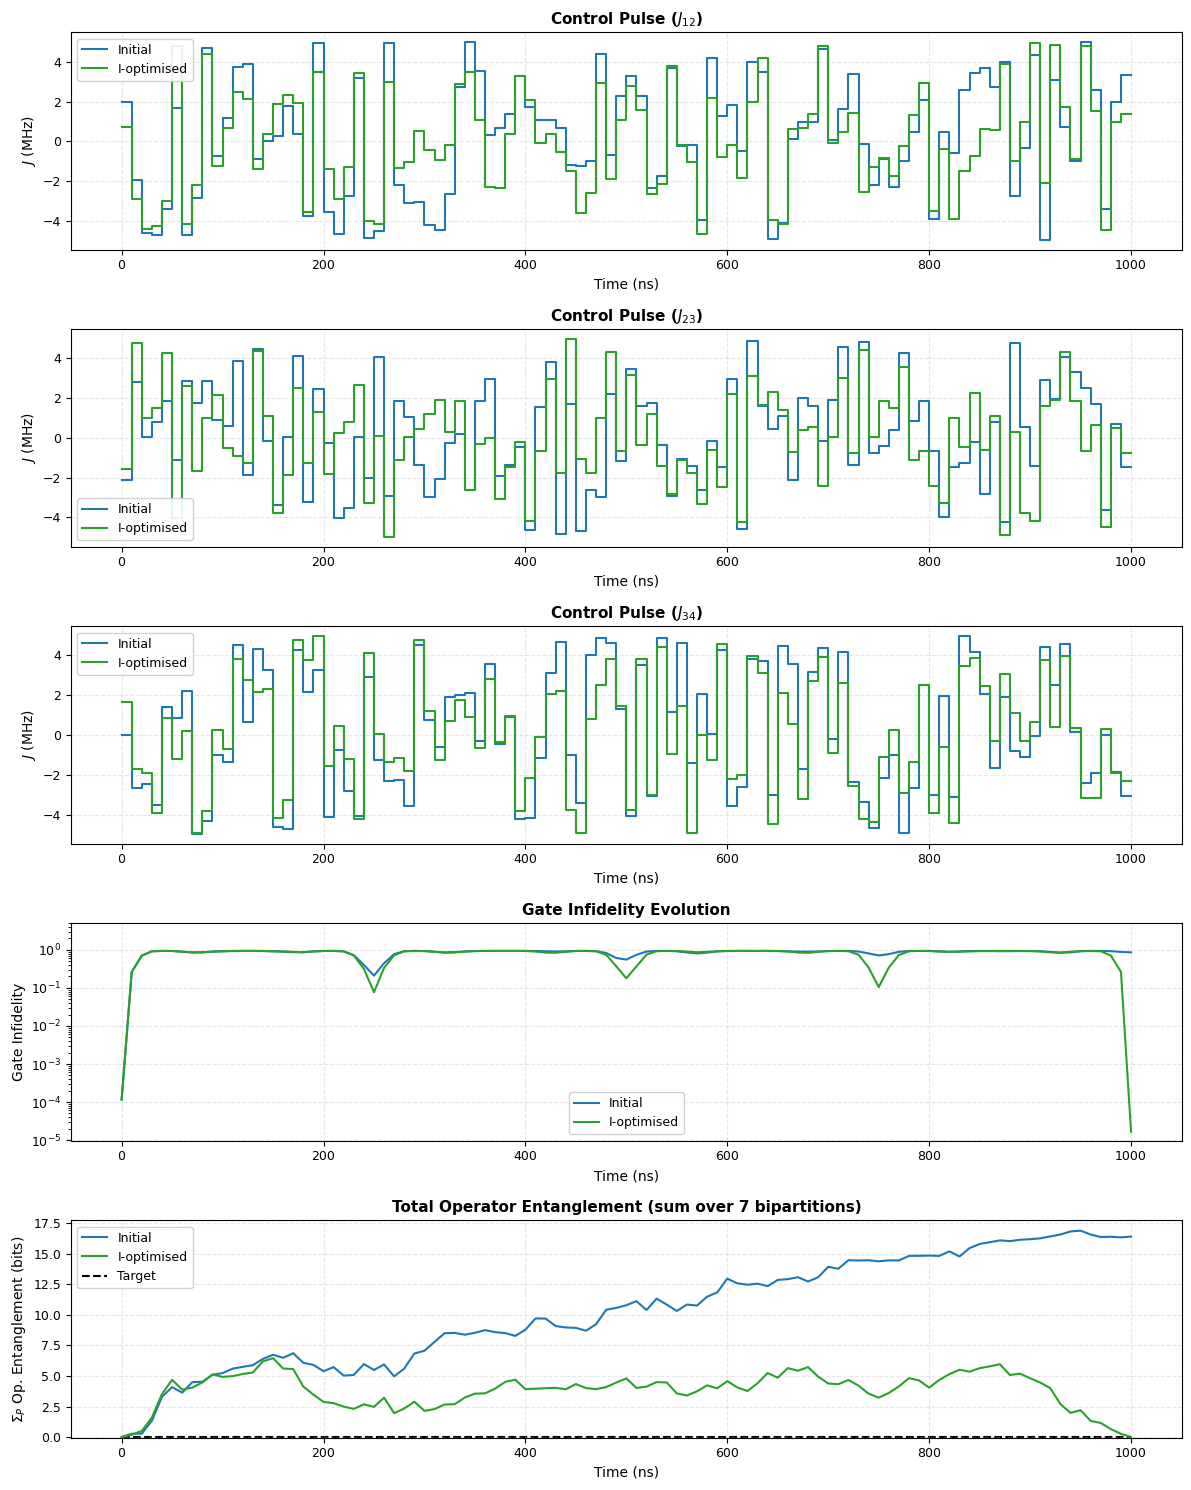

In [2]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0, 1016.0, 1024.0], dtype=float),
    initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
                            0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
                           dtype=np.complex128),  # |0011⟩
    theta_target=0.01 * np.pi,
    n_time_steps=100,
    n_discretisation=1,
    T=1000.0,
    J_max=-5.0,
    J_min=5.0,
    J_init_scale=1e0,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    optimisation_target="gate",
    entanglement_optimisation=False,
    gate_ent_measure="operator_entanglement_sum_4q",
    extra_ent_measures=[],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.5,
    eps_infidelity=1e-8,
    rho=0.0,
    dual_lr=1e12,
    n_outer=5,
    inner_maxiter=200,
    fd_eps=1e-6,
)

results = dqe_gate_optimisation(config)
plot_dqe_gate_optimisation(results)